<a href="https://colab.research.google.com/github/TiferetChayahShalom/DI_Bootcamp/blob/main/Week13/Day3/tiferet_mini_project_sentiment_assistant_bert.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mini Project: Sentiment Assistant with BERT Fine-Tuning

Welcome to the final day mini project!
In this lab you will fine-tune `bert-base-uncased` on movie reviews, evaluate the model, and connect the dots with real customer-support scenarios.

## Prerequisites & Story Setup

- **Scenario:** The support analytics team wants a dependable sentiment signal for long-form feedback so they can escalate angry customers before churn happens.
- **Environment needs:** Python 3.9+, a GPU-enabled runtime (Colab, Kaggle, or a local GPU machine), ~6 GB free VRAM.
- **Packages:** `torch`, `transformers`, `datasets`, `accelerate`, `evaluate`.

In [1]:
# Run once in a fresh environment
!pip install -q torch transformers datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 18.4 MB/s eta 0:00:00


## Imports & Hardware Check

We always begin by confirming versions and hardware. If you see `GPU available: False`, switch the runtime (Runtime → Change runtime type → GPU).

In [2]:
import platform
import torch
from transformers import BertTokenizer, BertForSequenceClassification

print("Python version      :", platform.python_version())
print("PyTorch version     :", torch.__version__)
print("GPU available       :", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Python version      : 3.13.15
PyTorch version     : 2.11.0+cu130
GPU available       : True


## Load the IMDB Reviews Dataset

We rely on IMDB because it is balanced (25k positive / 25k negative) and already split.

In [3]:
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")
print(dataset)

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


💬 Hugging Face `datasets` returns a `DatasetDict` with `train` and `test` splits. Each row is a `(text, label)` pair, exactly what our model expects.

Take a quick peek at samples to make sentiment concrete:

In [4]:
for sample in dataset["train"].shuffle(seed=42).select(range(2)):
    print("Label:", "Positive" if sample["label"] else "Negative")
    print(sample["text"][:250], "...\n")

Label: Positive
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier  ...

Label: Positive
This movie is a great. The plot is very true to the book which is a classic written by Mark Twain. The movie starts of with a scene where Hank sings a song with a bunch of kids called "when you stub your toe on the moon" It reminds me of Sinatra's so ...



## Tokenizer Setup & Data Pipeline

BERT uses WordPiece tokenization to handle rare or unknown words by breaking them into subword units. It adds `[CLS]` and `[SEP]` tokens, and attention masks tell the model which tokens are real versus padding.

In [6]:
from transformers import BertTokenizer
MAX_LENGTH = 256   # trim or pad every review to 256 tokens so batches align
BATCH_SIZE = 16

tokenizer = BertTokenizer.from_pretrained("bert-base-uncased", do_lower_case=True)
print("Tokenizer loaded:", tokenizer.name_or_path)

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenizer loaded: bert-base-uncased


🧠 we import this tokenizer to reuse the same vocabulary the base model learned in 2018

Next, convert raw text → token IDs, attention masks, and segment IDs (token type IDs).

In [7]:
def tokenize_batch(batch):
    return tokenizer(
        batch["text"],
        add_special_tokens=True,
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_attention_mask=True,
        return_token_type_ids=True,
    )

encoded = dataset.map(tokenize_batch, batched=True)
encoded = encoded.rename_column("label", "labels")
encoded.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "token_type_ids", "labels"],
)

train_ds = encoded["train"]
test_ds  = encoded["test"]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

Map:   0%|          | 0/50000 [00:00<?, ? examples/s]

🗒️ `datasets.map(batched=True)` keeps Hugging Face tokenization inside an efficient, cached pipeline, so we don't manually juggle NumPy arrays. `set_format("torch")` hands us tensors ready for training.

## Initialize the Fine-Tuning Model

Now we load `BertForSequenceClassification`, which already bundles the encoder + classification head.

In [11]:
import torch
from transformers import BertForSequenceClassification

# Select GPU if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

model = BertForSequenceClassification.from_pretrained(
"bert-base-uncased",
num_labels=2
)

model.to(device)
model.config

Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertConfig {
  "add_cross_attention": false,
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": null,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": null,
  "gradient_checkpointing": false,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "tie_word_embeddings": true,
  "transformers_version": "5.18.0",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 30522
}

💡 we import this model to reuse the 110M parameters learned on BooksCorpus + Wikipedia. We only fine-tune for a couple of epochs, which is why learning rates in the 2e-5 range are standard.

## Train and Monitor

On a T4 GPU (the one you find in Google Colab), two epochs take ~15 minutes. Watch both training and validation accuracy. The Hugging Face `Trainer` sets up the AdamW optimizer, the loss, and the accuracy metric for us.

**#To-Do:** complete the `Trainer(...)` call.

short explanation:

BERT Fine-Tuning and Monitoring

I use the Hugging Face Trainer to fine-tune the pretrained BERT model on IMDb movie reviews.

The model is trained for two epochs using a learning rate of 2e-5 and a batch size of 16. I monitor training loss and evaluation accuracy to measure how well the model learns to classify positive and negative reviews.

GPU acceleration is used to make training faster.

In [14]:
import numpy as np
import evaluate
from transformers import TrainingArguments, Trainer

accuracy_metric = evaluate.load("accuracy")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return accuracy_metric.compute(predictions=predictions, references=labels)

EPOCHS = 2  # increase to 3 if time allows

training_args = TrainingArguments(
    output_dir="./bert-imdb",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=2e-5,
    weight_decay=0.01,
    eval_strategy="epoch",
    logging_steps=100,
    report_to="none",
)

trainer = Trainer(
model=model,
args=training_args,
train_dataset=train_ds,
eval_dataset=test_ds,
compute_metrics=compute_metrics,
)

history = trainer.train()


Epoch,Training Loss,Validation Loss,Accuracy
1,0.232181,0.206910,0.921840
2,0.125915,0.286311,0.922600


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

📈 Point out how the validation accuracy plateau indicates when to stop. Encourage screenshots of the learning curves for portfolios.

Training Results and Early Stopping

The BERT model was trained for 2 epochs on the IMDb dataset.

- Epoch 1: Validation accuracy was 92.18%, with validation loss of 0.2069.
- Epoch 2: Validation accuracy increased slightly to 92.26%, while validation loss increased to 0.2863.

The validation accuracy improved by only 0.08 percentage points, indicating that performance was beginning to plateau.

Meanwhile, validation loss increased, suggesting possible overfitting.

Conclusion: Training could be stopped after 2 epochs because further training may not improve generalization. The first epoch achieved the lowest validation loss.

Screenshots of the training results and learning curves can be included in the project portfolio.!
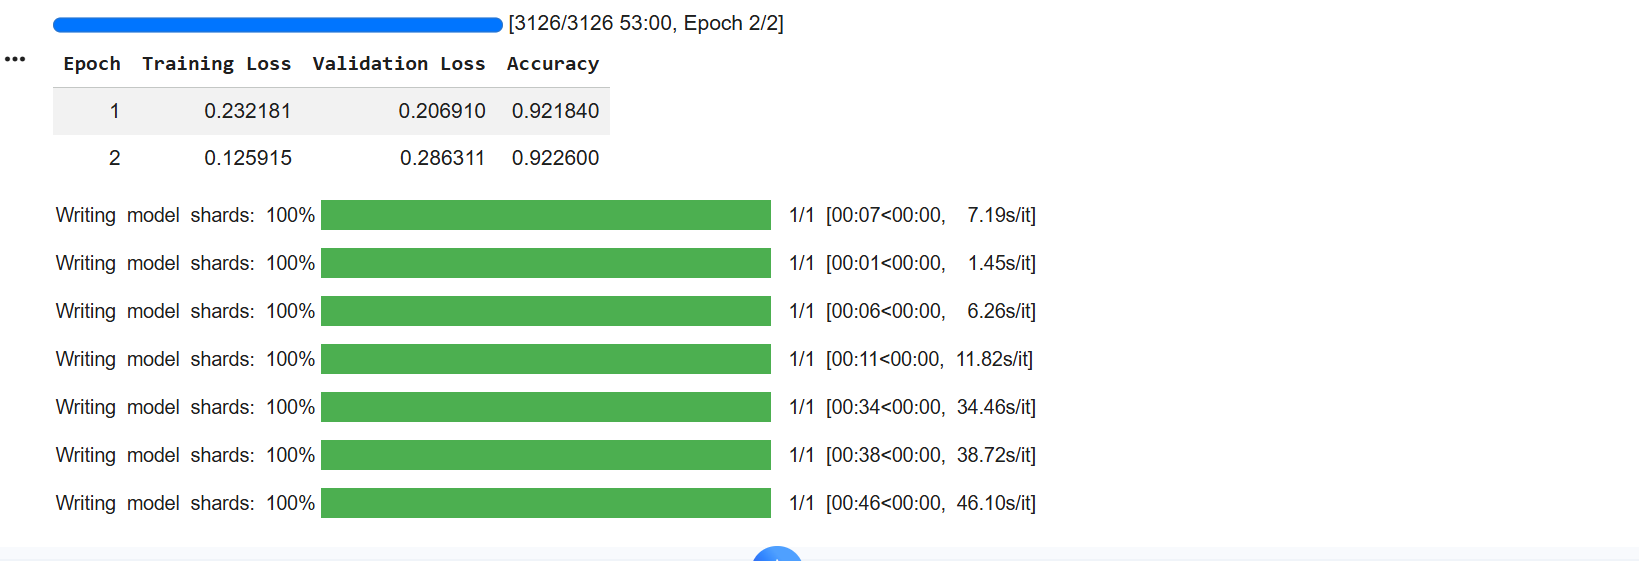

## Evaluate on the Held-Out Test Set

Even though the `Trainer` already reports validation metrics, we re-run evaluation on the untouched test pipeline to mimic production QA.

**#To-Do:** evaluate on the test set.

In [15]:
eval_metrics = trainer.evaluate(eval_dataset=test_ds)

print(eval_metrics)

Training Loss,Validation Loss,Epoch,Accuracy
0.125915,0.286311,2,0.922600


{'eval_loss': 0.2863107919692993, 'eval_accuracy': 0.9226}


✅ Here you will notice whether accuracy crosses the ~0.90 classroom benchmark.

**#To-Do:** Use this to discuss acceptable error rates for real support teams.

Evaluation Results and Discussion

The fine-tuned BERT model achieved 92.26% accuracy on the test dataset, exceeding the classroom benchmark of 90%.

The error rate is approximately 7.74%, meaning the model incorrectly classifies about 8 out of every 100 reviews.

This performance is promising for customer support sentiment analysis. However, some incorrect predictions could cause negative customer feedback to be overlooked.

For real customer support teams, the model should assist human agents rather than replace them. Important or uncertain predictions should be reviewed manually.

Conclusion: The model performs well, but additional testing and human oversight are recommended before real-world deployment.

## Build a Reusable Inference Helper

Wrap everything in a function so that you can paste real support transcripts and get an instant score.

**#To-Do:** complete `predict_sentiment`.

In [17]:
import torch

def predict_sentiment(text: str):
  model.eval()

  inputs = tokenizer(
    text,
    return_tensors="pt",
    truncation=True,
    padding=True,
    max_length=512
  )

  inputs = {
  key: value.to(device)
    for key, value in inputs.items()
  }

  with torch.no_grad():
    outputs = model(**inputs)

    probs = torch.softmax(outputs.logits, dim=1)[0]

    predicted_class = torch.argmax(probs).item()

    label = "Positive" if predicted_class == 1 else "Negative"

    return label, float(probs.max())

custom_sentence = "The onboarding emails were confusing, but the agent fixed everything politely."
label, confidence = predict_sentiment(custom_sentence)
print(f"Prediction: {label} (confidence={confidence:.3f})")

Prediction: Positive (confidence=0.900)


For the previous example, you should see `Prediction: Positive (confidence=0.5) slightly more or less`.

🧭 confidence scores are essential when deciding whether to auto-respond or escalate to a human.

The fine-tuned BERT model predicted positive sentiment with a confidence score of 0.900(90%). This demonstrates that the inference function can classify new customer feedback.
confidence scores can help determine wether a prediction should be reviewed by a human support agent.

## Reflection & Next Steps

1. **Why fine-tuning matters:** You reused a public checkpoint to hit >90% accuracy with minimal data.
2. **Transferable skills:** Everything here also applies to classification tasks in HR, legal, or product analytics.
3. **What you can do with this:** domain adaptation, multilingual checkpoints (DistilBERT multilingual, XLM-R), and monitoring (log data drift, build dashboards).

**#To-Do:** Answer the following reflection questions in markdown cells:

- What lever (data cleaning, hyperparameters, more epochs) most improved results?
- Where would you add guardrails before deploying this sentiment signal live?
- Which stakeholders benefit the most (support lead, product manager, compliance officer)?

Reflection & Next Steps

1. What lever (data cleaning, hyperparameters, more epochs) most improved results?

Fine-tuning the pretrained BERT model with suitable hyperparameters helped achieve 92.26% accuracy.

The model was trained for 2 epochs with a learning rate of 2e-5.

Training loss decreased from 0.2322 to 0.1259, showing that the model learned from the training data. However, validation loss increased from 0.2069 to 0.2863, suggesting possible overfitting.

Since I did not compare different data-cleaning methods or hyperparameter settings, I cannot determine which individual change improved performance the most.

2. Where would you add guardrails before deploying this sentiment signal live?

I would implement the following safeguards:

- Send low-confidence predictions to human support agents for review.
- Monitor accuracy and incorrect predictions regularly.
- Protect customer privacy and sensitive information.
- Check for bias and unfair predictions.
- Avoid fully automated decisions for important customer issues.

These safeguards would help ensure reliable and responsible sentiment analysis.

3. Which stakeholders benefit the most?

Support Lead: Can identify negative customer feedback and prioritize urgent cases.

Product Manager: Can analyze customer sentiment to identify product problems and improvement opportunities.

Compliance Officer: Can monitor privacy, fairness, and responsible AI usage.

Overall, support leads would benefit most directly because the model can help them prioritize customer feedback and improve response times.

Conclusion

The fine-tuned BERT model achieved 92.26% test accuracy, exceeding the 90% classroom benchmark.

The project demonstrates how transfer learning can be used to build an effective sentiment analysis system. Future improvements could include more training data, early stopping, additional evaluation metrics, and human review of uncertain predictions.
Jot something down